The goal is to install clingo and write the answer in ASP
first step: install dependencies and more importantly the clingo

In [2]:
!sudo add-apt-repository -y ppa:potassco/stable
!sudo apt-get update
!apt install clingo

Repository: 'Types: deb
URIs: https://ppa.launchpadcontent.net/potassco/stable/ubuntu/
Suites: noble
Components: main
'
Description:
Contains the stable releases of systems from the https://potassco.org project.
More info: https://launchpad.net/~potassco/+archive/ubuntu/stable
Adding repository.
Get:1 https://cli.github.com/packages stable InRelease [3,917 B]
Get:2 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease [3,631 B]
Get:3 http://security.ubuntu.com/ubuntu noble-security InRelease [126 kB]
Hit:4 http://archive.ubuntu.com/ubuntu noble InRelease
Get:5 http://archive.ubuntu.com/ubuntu noble-updates InRelease [126 kB]
Get:6 https://r2u.stat.illinois.edu/ubuntu noble InRelease [9,161 B]
Get:7 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ Packages [78.0 kB]
Get:8 http://archive.ubuntu.com/ubuntu noble-backports InRelease [126 kB]
Get:9 https://cli.github.com/packages stable/main amd64 Packages [357 B]
Get:10 https://ppa.launchpadcontent.net/deadsnakes/p

we should test that clingo is working with a simple sample

In [ ]:
# to test clingo running in colab, you can use the following code snippet:
%%script bash --no-raise-error -c "clingo - 0"
{a}.
b :- a.
:- not b.


clingo version 5.8.3 (2ef9164)
Reading from -
Solving...
Answer: 1 (Time: 0.000s)
b a
SATISFIABLE

Models       : 1
Calls        : 1
Time         : 0.000s (Solving: 0.00s 1st Model: 0.00s Unsat: 0.00s)
CPU Time     : 0.000s


ok, clingo is installed. now I should be able to test my solution with it.

In [ ]:
# pass asp code directly to clingo command prompt
%%script bash --no-raise-error -c "clingo - 0"
% Please insert the names and email addresses of the group members:
%
%

subgrid_size(3).

num(1..9).
row(1..9).
col(1..9).

1 { sudoku(X,Y,N) : num(N) } 1 :- row(X), col(Y).

sudoku(X,Y,N) :- initial(X,Y,N).

:- sudoku(X,Y1,N), sudoku(X,Y2,N), Y1 < Y2.
:- sudoku(X1,Y,N), sudoku(X2,Y,N), X1 < X2.
:- sudoku(X1,Y1,N), sudoku(X2,Y2,N), (X1,Y1) < (X2,Y2), subgrid_size(S), ((X1-1)/S) = ((X2-1)/S), ((Y1-1)/S) = ((Y2-1)/S).

#show sudoku/3.


bash: line 1: clingo: command not found


the correct way to use it is to pass 1. the asp code and then 2. the example file

In [3]:
%%script bash --no-raise-error
clingo /content/drive/MyDrive/Ai-Course/project-sudoku/asp/sudoku.lp /content/drive/MyDrive/Ai-Course/project-sudoku/asp/instances/ex00.lp

clingo version 5.8.2 (a99ffb2)
Reading from ...Ai-Course/project-sudoku/asp/sudoku.lp ...
Solving...
Answer: 1 (Time: 0.336s)
sudoku(2,4,1) sudoku(8,5,1) sudoku(5,9,1) sudoku(6,5,2) sudoku(7,7,2) sudoku(1,2,3) sudoku(5,6,3) sudoku(4,9,3) sudoku(5,1,4) sudoku(8,4,4) sudoku(1,1,5) sudoku(2,6,5) sudoku(8,9,5) sudoku(2,1,6) sudoku(7,2,6) sudoku(4,5,6) sudoku(3,8,6) sudoku(6,9,6) sudoku(6,1,7) sudoku(1,5,7) sudoku(9,8,7) sudoku(4,1,8) sudoku(3,3,8) sudoku(5,4,8) sudoku(9,5,8) sudoku(7,8,8) sudoku(3,2,9) sudoku(2,5,9) sudoku(8,6,9) sudoku(9,9,9) sudoku(1,3,4) sudoku(3,1,1) sudoku(2,3,2) sudoku(2,2,7) sudoku(4,2,5) sudoku(4,3,9) sudoku(5,2,2) sudoku(5,3,6) sudoku(7,3,1) sudoku(8,1,2) sudoku(7,1,9) sudoku(9,1,3) sudoku(8,3,7) sudoku(8,2,8) sudoku(6,2,1) sudoku(9,2,4) sudoku(6,3,3) sudoku(9,3,5) sudoku(1,4,6) sudoku(1,6,8) sudoku(3,4,3) sudoku(4,6,1) sudoku(4,4,7) sudoku(5,5,5) sudoku(6,4,9) sudoku(7,5,3) sudoku(7,4,5) sudoku(7,6,7) sudoku(9,4,2) sudoku(3,5,4) sudoku(3,6,2) sudoku(6,6,4) sudoku

In [6]:
%%script bash --no-raise-error
BASE="/content/drive/MyDrive/Ai-Course/project-sudoku/asp"

for i in {00..18}; do
    echo "=================================================="
    echo "Running: ex$i.lp"
    echo "=================================================="
    clingo "$BASE/sudoku.lp" "$BASE/instances/ex$i.lp" 0
    echo -e "\n"
done

Output hidden; open in https://colab.research.google.com to view.

now for all the files I should do the same so a appropriate option is run a for loop agains all the example files

In [7]:
import subprocess
import json

base_dir = "/content/drive/MyDrive/Ai-Course/project-sudoku/asp"
solver_path = f"{base_dir}/sudoku.lp"

for i in range(19):
    instance_name = f"ex{i:02d}.lp"
    instance_path = f"{base_dir}/instances/{instance_name}"

    # Run clingo with --outf=2 to get JSON output
    result = subprocess.run(
        ["clingo", solver_path, instance_path, "0", "--outf=2"],
        text=True,
        capture_output=True
    )

    print(f"=== Result for {instance_name} ===")

    if result.returncode in (0, 30) and result.stdout.strip():
        try:
            # Parse and nicely print the JSON matching your teacher's format
            data = json.loads(result.stdout)
            print(json.dumps(data, indent=2))
        except json.JSONDecodeError:
            print("Could not parse JSON output:")
            print(result.stdout)
    else:
        print(result.stderr)
    print("\n")

Streaming output truncated to the last 5000 lines.
            "sudoku(8,4,2)",
            "sudoku(5,5,2)",
            "sudoku(1,6,2)",
            "sudoku(3,7,2)",
            "sudoku(6,8,2)",
            "sudoku(3,4,3)",
            "sudoku(4,5,3)",
            "sudoku(7,6,3)",
            "sudoku(6,7,3)",
            "sudoku(9,8,3)",
            "sudoku(2,9,3)",
            "sudoku(7,4,4)",
            "sudoku(3,5,4)",
            "sudoku(6,6,4)",
            "sudoku(2,7,4)",
            "sudoku(8,8,4)",
            "sudoku(5,9,4)",
            "sudoku(4,4,5)",
            "sudoku(1,5,5)",
            "sudoku(8,6,5)",
            "sudoku(5,7,5)",
            "sudoku(3,8,5)",
            "sudoku(7,9,5)",
            "sudoku(5,4,6)",
            "sudoku(2,5,6)",
            "sudoku(9,6,6)",
            "sudoku(1,7,6)",
            "sudoku(7,8,6)",
            "sudoku(6,9,6)",
            "sudoku(6,4,7)",
            "sudoku(7,5,7)",
            "sudoku(2,6,7)",
            "sudoku(9

so, let's visualise all them just like in the original file. helps with understanding the game.

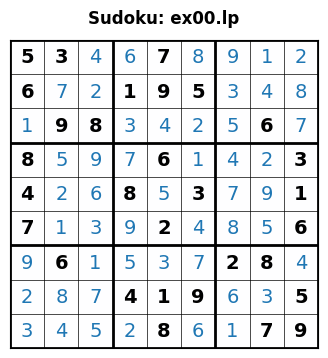

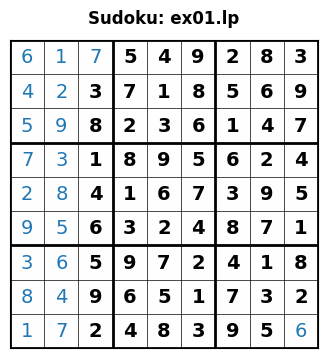

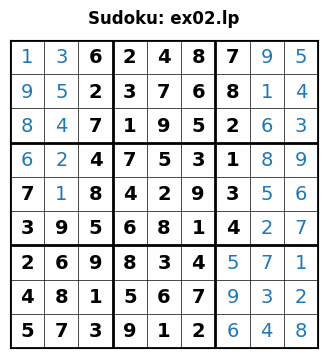

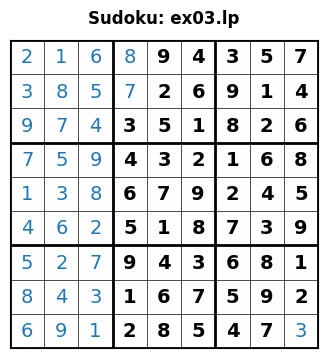

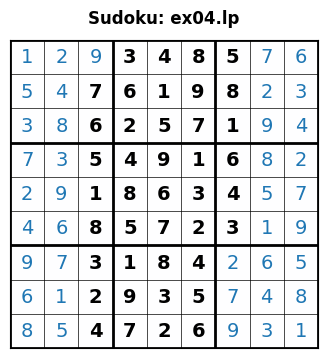

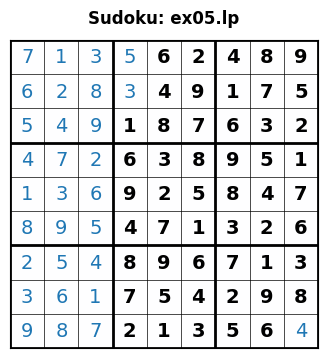

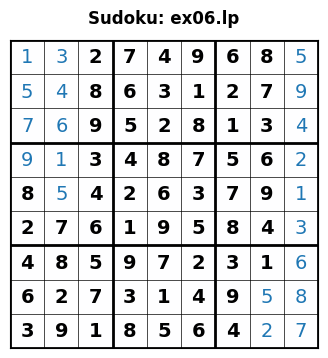

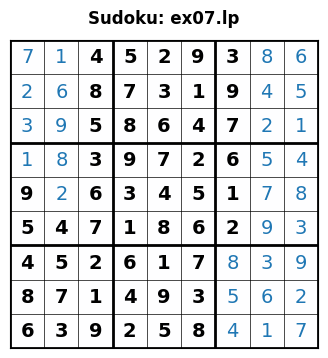

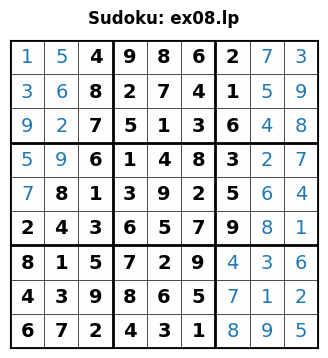

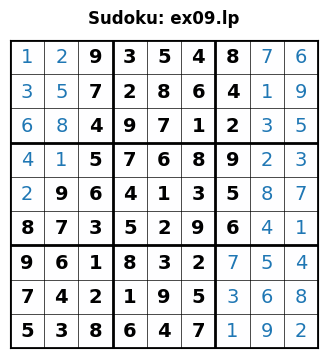

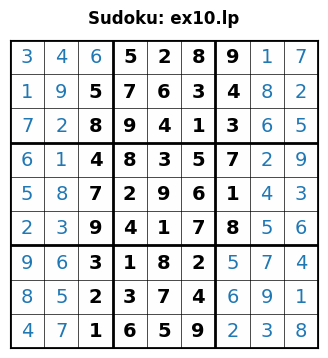

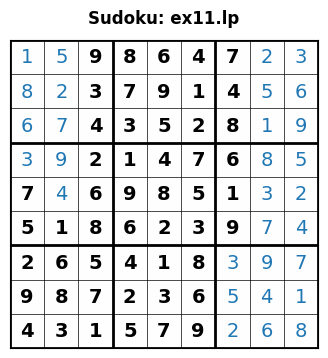

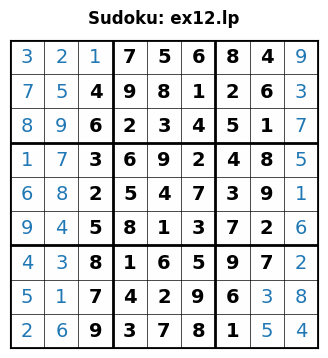

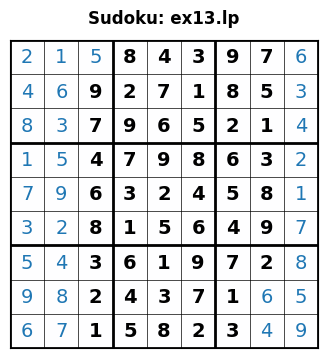

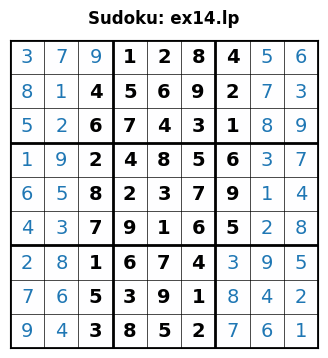

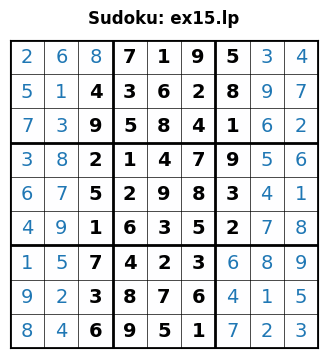

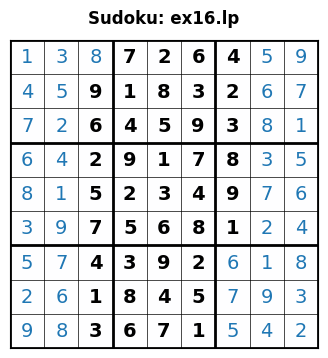

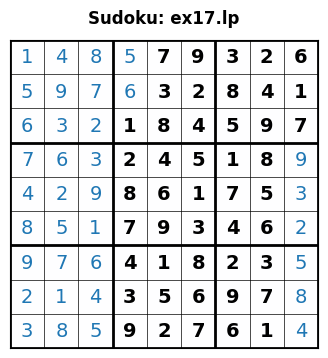

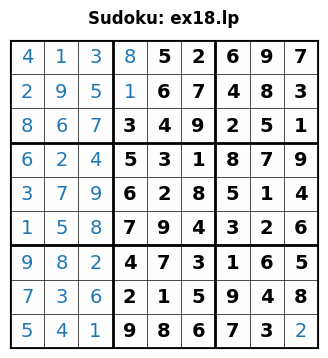

In [7]:
import subprocess
import json
import re
import matplotlib.pyplot as plt
import numpy as np

# Define your directory paths
base_dir = "/content/drive/MyDrive/Ai-Course/project-sudoku/asp"
solver_path = f"{base_dir}/sudoku.lp"

def parse_initial_file(instance_path):
    """Reads the instance file and extracts initial(r,c,v) values."""
    initial_cells = {}
    try:
        with open(instance_path, 'r') as f:
            content = f.read()
            # Match patterns like initial(1,1,5)
            matches = re.findall(r'initial\((\d+),\s*(\d+),\s*(\d+)\)', content)
            for r, c, val in matches:
                initial_cells[(int(r), int(c))] = int(val)
    except Exception as e:
        print(f"Could not read instance file {instance_path}: {e}")
    return initial_cells

def plot_sudoku_grid(witness_values, initial_cells, title="Sudoku Solution"):
    """
    Plots a 9x9 Sudoku board:
    - Initial clues are colored BLACK.
    - Solved numbers are colored BLUE.
    """
    board = np.zeros((9, 9), dtype=int)

    # Extract values from clingo witness format (e.g., "sudoku(1,1,5)")
    for v in witness_values:
        match = re.match(r'sudoku\((\d+),(\d+),(\d+)\)', v)
        if match:
            r, c, val = map(int, match.groups())
            board[r-1, c-1] = val  # 0-indexed for matplotlib

    # Create figure
    fig, ax = plt.subplots(figsize=(4, 4), dpi=100)
    ax.matshow(np.zeros((9, 9)), cmap='Blues', alpha=0.1)

    # Draw standard 9x9 grid lines with thicker lines for 3x3 subgrids
    for i in range(10):
        lw = 2 if i % 3 == 0 else 0.5
        ax.axhline(i - 0.5, color='black', linewidth=lw)
        ax.axvline(i - 0.5, color='black', linewidth=lw)

    # Fill numbers into the grid cells with distinct colors
    for i in range(9):
        for j in range(9):
            val = board[i, j]
            if val != 0:
                r_1based, c_1based = i + 1, j + 1

                # Distinguish initial clues from solved numbers
                if (r_1based, c_1based) in initial_cells:
                    color = 'black'
                    weight = 'bold'
                else:
                    color = '#1f77b4' # Blue color for solution numbers
                    weight = 'normal'

                ax.text(j, i, str(val), va='center', ha='center', fontsize=14, fontweight=weight, color=color)

    # Clean up axes ticks
    ax.set_xticks([])
    ax.set_yticks([])
    plt.title(title, fontsize=12, fontweight='bold', pad=12)
    plt.show()

# Loop through all example files from ex00 to ex18
for i in range(19):
    instance_name = f"ex{i:02d}.lp"
    instance_path = f"{base_dir}/instances/{instance_name}"

    # 1. Parse initial clues from the instance file
    initial_cells = parse_initial_file(instance_path)

    # 2. Run clingo with JSON output flag (--outf=2)
    result = subprocess.run(
        ["clingo", solver_path, instance_path, "0", "--outf=2"],
        text=True,
        capture_output=True
    )

    if result.returncode in (0, 30) and result.stdout.strip():
        try:
            data = json.loads(result.stdout)

            # Extract values from the first witness model
            if data.get("Call") and data["Call"][0].get("Witnesses"):
                values = data["Call"][0]["Witnesses"][0]["Value"]
                plot_sudoku_grid(values, initial_cells, title=f"Sudoku: {instance_name}")
            else:
                print(f"No solution found for {instance_name}")

        except json.JSONDecodeError:
            print(f"Failed to parse JSON for {instance_name}")
    else:
        print(f"Error running {instance_name}")

to test my solutions against the original solutions. I need to save them on files and then compare them.
so, saving my solutions:

In [10]:
import subprocess
import os

base_dir = "/content/drive/MyDrive/Ai-Course/project-sudoku/asp"

# Where to save your generated JSON files
# output_dir = f"{base_dir}/solutions"
output_dir = f"{base_dir}/my_solutions"
os.makedirs(output_dir, exist_ok=True)

for i in range(19):
    base_name = f"ex{i:02d}"

    # Must use relative paths so the JSON "Input" array matches ["sudoku.lp", "instances/ex00.lp"]
    solver_rel = "sudoku.lp"
    instance_rel = f"instances/{base_name}.lp"

    output_json_path = f"{output_dir}/{base_name}.json"

    # Run clingo from inside base_dir
    result = subprocess.run(
        ["clingo", solver_rel, instance_rel, "0", "--outf=2"],
        cwd=base_dir,
        text=True,
        capture_output=True
    )

    if result.returncode in (0, 10, 20, 30) and result.stdout.strip():
        # Write clingo's raw stdout directly to preserve exact spacing and 0.000 decimals
        with open(output_json_path, "w", encoding="utf-8") as f:
            f.write(result.stdout)
        print(f"Saved {output_json_path}")
    else:
        print(f"Error on {base_name}: {result.stderr}")

Saved /content/drive/MyDrive/Ai-Course/project-sudoku/asp/solutions/ex00.json
Saved /content/drive/MyDrive/Ai-Course/project-sudoku/asp/solutions/ex01.json
Saved /content/drive/MyDrive/Ai-Course/project-sudoku/asp/solutions/ex02.json
Saved /content/drive/MyDrive/Ai-Course/project-sudoku/asp/solutions/ex03.json
Saved /content/drive/MyDrive/Ai-Course/project-sudoku/asp/solutions/ex04.json
Saved /content/drive/MyDrive/Ai-Course/project-sudoku/asp/solutions/ex05.json
Saved /content/drive/MyDrive/Ai-Course/project-sudoku/asp/solutions/ex06.json
Saved /content/drive/MyDrive/Ai-Course/project-sudoku/asp/solutions/ex07.json
Saved /content/drive/MyDrive/Ai-Course/project-sudoku/asp/solutions/ex08.json
Saved /content/drive/MyDrive/Ai-Course/project-sudoku/asp/solutions/ex09.json
Saved /content/drive/MyDrive/Ai-Course/project-sudoku/asp/solutions/ex10.json
Saved /content/drive/MyDrive/Ai-Course/project-sudoku/asp/solutions/ex11.json
Saved /content/drive/MyDrive/Ai-Course/project-sudoku/asp/soluti

test the first solutions (mine against teacher)

In [13]:
import json

with open(f"{base_dir}/my_solutions/ex00.json") as f1, open(f"{base_dir}/solutions/ex00.json") as f2:
    my_ans = json.load(f1)
    teacher_ans = json.load(f2)

my_values = set(my_ans["Call"][0]["Witnesses"][0]["Value"])
teacher_values = set(teacher_ans["Call"][0]["Witnesses"][0]["Value"])

print("Exact same 81 Sudoku cells?", my_values == teacher_values)
print("Exact same Result & Models?",
      my_ans["Result"] == teacher_ans["Result"] and
      my_ans["Models"] == teacher_ans["Models"])

Exact same 81 Sudoku cells? True
Exact same Result & Models? True


now test all the solutions in a for loop (mine against teacher)

In [15]:
import json
import os

base_dir = "/content/drive/MyDrive/Ai-Course/project-sudoku/asp"

# Counters to track your overall score across all 19 test cases
passed_count = 0
total_files = 19

for i in range(total_files):
    file_name = f"ex{i:02d}.json"
    my_file_path = f"{base_dir}/my_solutions/{file_name}"
    teacher_file_path = f"{base_dir}/solutions/{file_name}"

    # 1. Check that both files actually exist before opening them
    if not os.path.exists(my_file_path):
        print(f"[MISSING] {file_name}: Your solution file was not found.")
        continue
    if not os.path.exists(teacher_file_path):
        print(f"[MISSING] {file_name}: Teacher's solution file was not found.")
        continue

    # 2. Load both JSON files
    with open(my_file_path, "r", encoding="utf-8") as f1, \
         open(teacher_file_path, "r", encoding="utf-8") as f2:
        my_ans = json.load(f1)
        teacher_ans = json.load(f2)

    # 3. Compare "Result" (e.g., SATISFIABLE vs UNSATISFIABLE) and "Models"
    same_result = (my_ans.get("Result") == teacher_ans.get("Result"))
    same_models = (my_ans.get("Models") == teacher_ans.get("Models"))

    # 4. Safely extract and compare all Witnesses (solutions)
    # Using .get("Witnesses", []) avoids a KeyError if a puzzle is UNSATISFIABLE.
    # Converting each witness's "Value" list into a frozenset allows us to compare
    # puzzles even if they have 0, 1, or multiple valid solutions in any order.
    my_witnesses = {
        frozenset(w["Value"])
        for w in my_ans["Call"][0].get("Witnesses", [])
    }
    teacher_witnesses = {
        frozenset(w["Value"])
        for w in teacher_ans["Call"][0].get("Witnesses", [])
    }

    same_cells = (my_witnesses == teacher_witnesses)

    # 5. Print status for the current file
    if same_result and same_models and same_cells:
        passed_count += 1
        print(f"✅ {file_name}: PASS (Result: {my_ans.get('Result')}, Models: {my_ans['Models']['Number']})")
    else:
        print(f"❌ {file_name}: FAIL")
        print(f"   - Same Result? {same_result} (Yours: {my_ans.get('Result')} vs Teacher: {teacher_ans.get('Result')})")
        print(f"   - Same Models? {same_models} (Yours: {my_ans.get('Models')} vs Teacher: {teacher_ans.get('Models')})")
        print(f"   - Same Sudoku cells? {same_cells}")

print("-" * 50)
print(f"Final Summary: {passed_count}/{total_files} test cases matched perfectly!")

✅ ex00.json: PASS (Result: SATISFIABLE, Models: 1)
✅ ex01.json: PASS (Result: SATISFIABLE, Models: 8)
✅ ex02.json: PASS (Result: SATISFIABLE, Models: 12)
✅ ex03.json: PASS (Result: SATISFIABLE, Models: 168)
✅ ex04.json: PASS (Result: SATISFIABLE, Models: 112)
✅ ex05.json: PASS (Result: SATISFIABLE, Models: 288)
✅ ex06.json: PASS (Result: SATISFIABLE, Models: 1)
✅ ex07.json: PASS (Result: SATISFIABLE, Models: 8)
✅ ex08.json: PASS (Result: SATISFIABLE, Models: 4)
✅ ex09.json: PASS (Result: SATISFIABLE, Models: 8)
✅ ex10.json: PASS (Result: SATISFIABLE, Models: 280)
✅ ex11.json: PASS (Result: SATISFIABLE, Models: 12)
✅ ex12.json: PASS (Result: SATISFIABLE, Models: 16)
✅ ex13.json: PASS (Result: SATISFIABLE, Models: 28)
✅ ex14.json: PASS (Result: SATISFIABLE, Models: 180)
✅ ex15.json: PASS (Result: SATISFIABLE, Models: 728)
✅ ex16.json: PASS (Result: SATISFIABLE, Models: 444)
✅ ex17.json: PASS (Result: SATISFIABLE, Models: 924)
✅ ex18.json: PASS (Result: SATISFIABLE, Models: 180)
---------